## Courier Delivery Sequencing Under Sparse and Dense Receipt Activity (Flag 3)

### Dataset Overview
The main table contains 108 order receipt and completion events across six courier-days. The supporting table contains six timestamped, road-aligned Shanghai trajectories generated from cached OSRM road geometry.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Detect repeated delivery-sequencing patterns by relating the courier's road-network trajectories to order receipt and destination events across multiple days.

Role: Last-mile delivery operations analyst


Category: Courier and Order Insight

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "orders.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: When the courier has a sparse batch of pending destinations, is the nearest destination consistently completed next?

#### Analysis action

Compare receipt-to-destination distance with completion order separately within every repeated sparse batch.

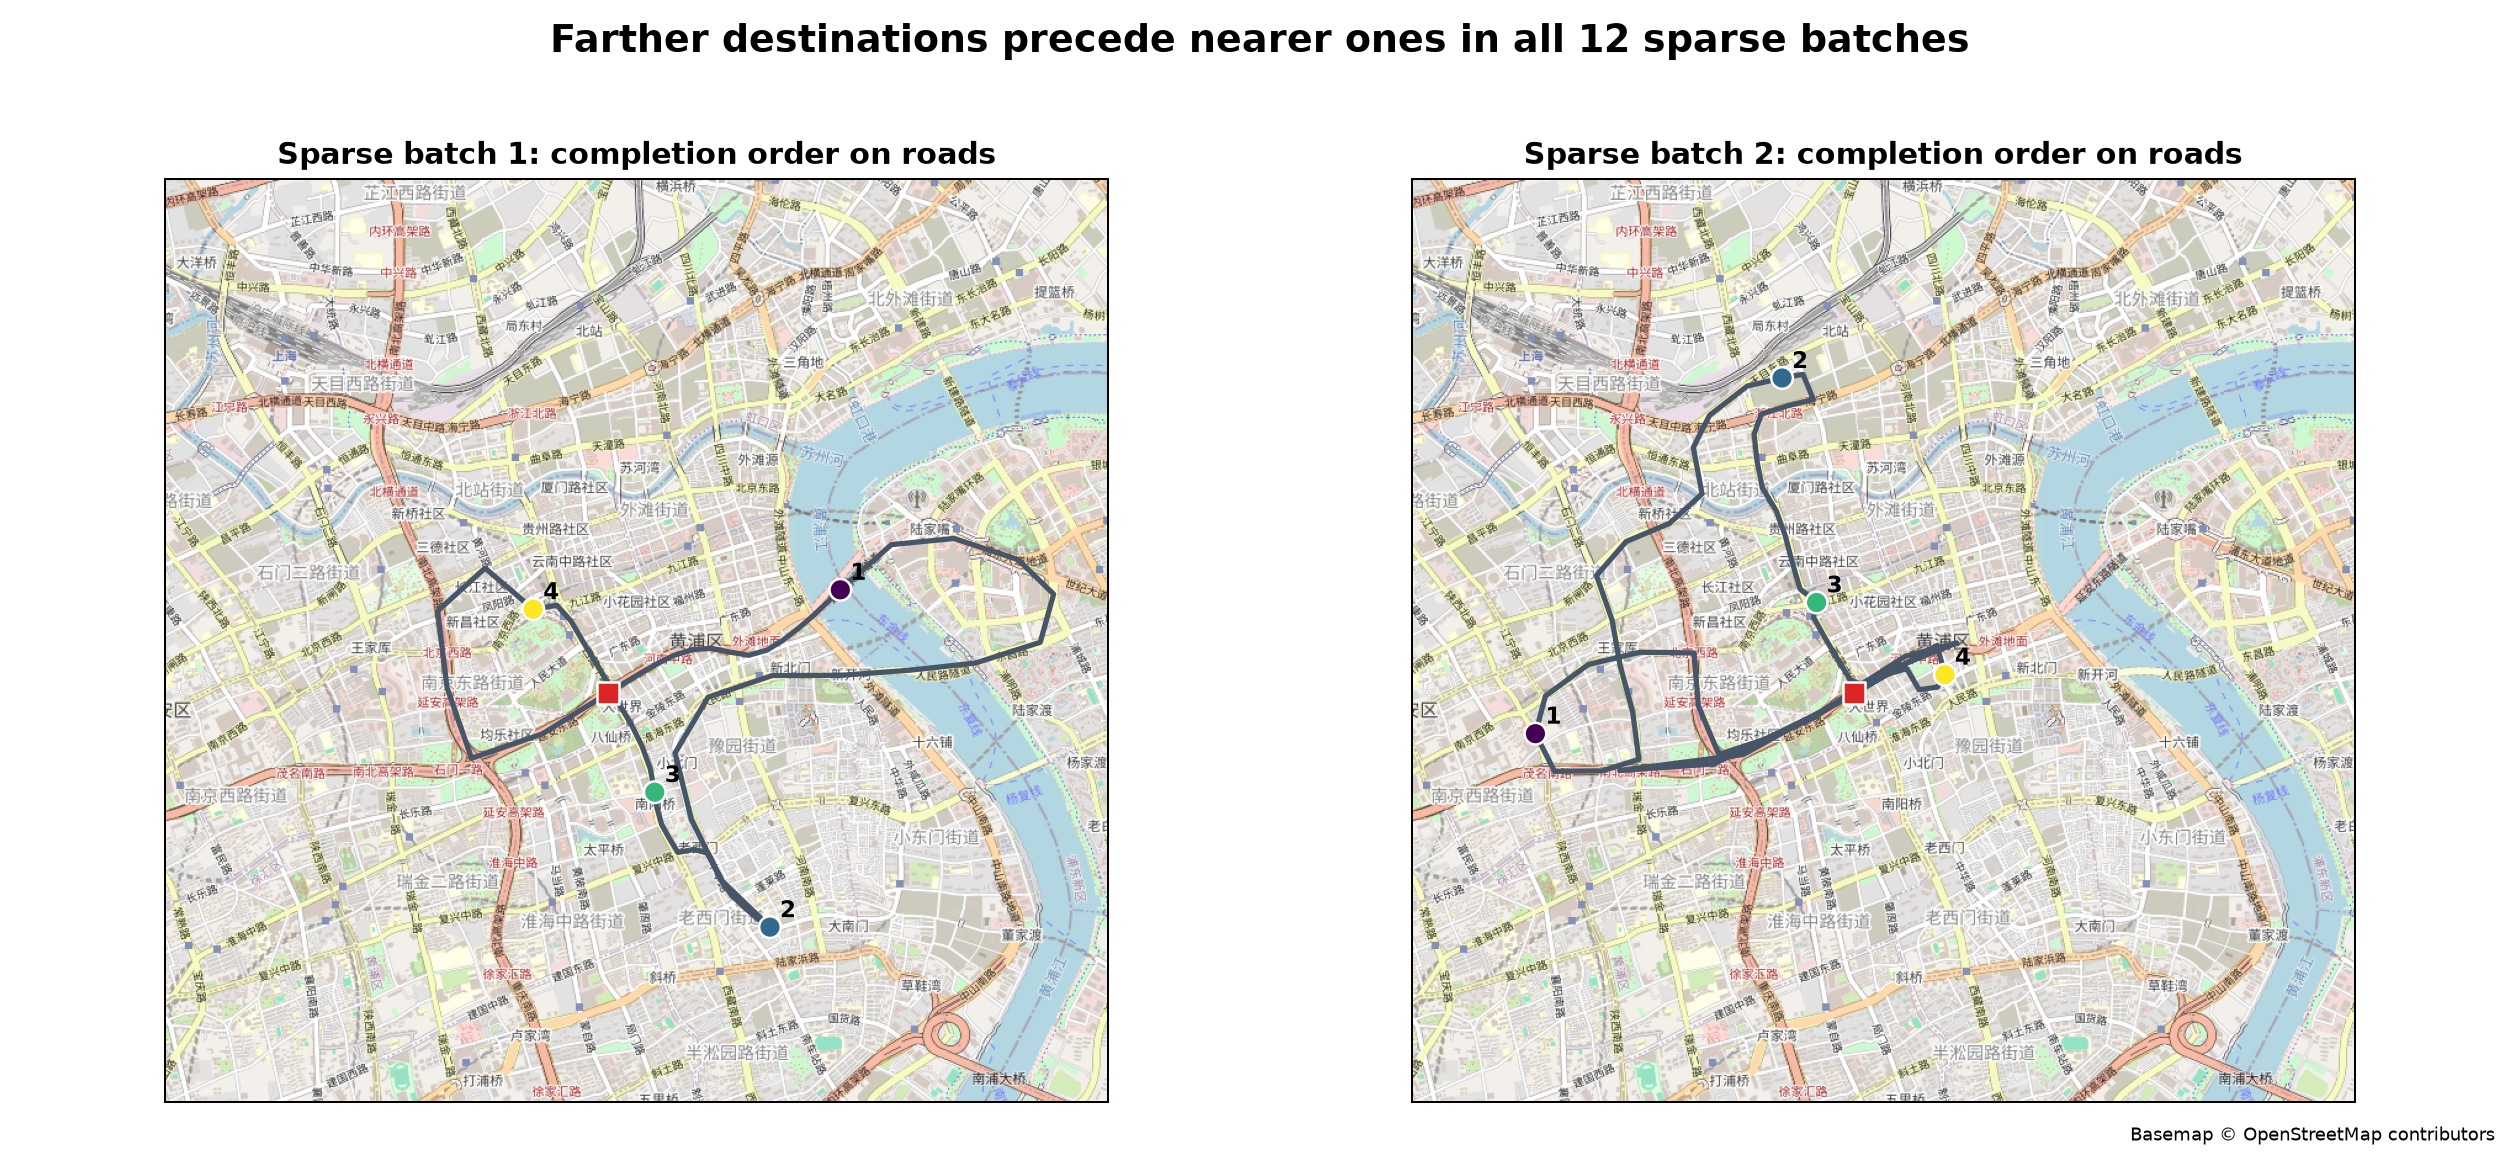

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
d = df.copy()
d['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])
for c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])
def haversine(lon1,lat1,lon2,lat2):
    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))
d['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)
sparse=d.groupby(['ds','receipt_time']).filter(lambda q: len(q)==4).sort_values(['ds','receipt_time','sign_time'])
checks=sparse.groupby(['ds','receipt_time']).apply(lambda q:q.iloc[:2].destination_distance_km.min()>q.iloc[2:].destination_distance_km.max())
print('Sparse batches:',len(checks),'farther-before-closer batches:',int(checks.sum()))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/sparse_completion_sequence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "diagnostic",
  "insight_type": "factor_relationship",
  "insight": "The courier does not consistently complete the destination nearest to the current position next.",
  "insight_value": {
    "sparse_batches": 12,
    "farther_before_closer_batches": 12
  },
  "plot": {
    "plot_type": "trajectory_order_map",
    "title": "Repeated Sparse Batches and Completion Sequence",
    "file": "visualizations/sparse_completion_sequence.png",
    "description": "Representative road-aligned sparse routes show completion order and replication across all sparse batches."
  },
  "question": "When the courier has a sparse batch of pending destinations, is the nearest destination consistently completed next?",
  "actionable_insight": "Compare receipt-to-destination distance with completion order separately within every repeated sparse batch.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nd = df.copy()\nd['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])\nfor c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])\ndef haversine(lon1,lat1,lon2,lat2):\n    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)\n    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2\n    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))\nd['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)\nsparse=d.groupby(['ds','receipt_time']).filter(lambda q: len(q)==4).sort_values(['ds','receipt_time','sign_time'])\nchecks=sparse.groupby(['ds','receipt_time']).apply(lambda q:q.iloc[:2].destination_distance_km.min()>q.iloc[2:].destination_distance_km.max())\nprint('Sparse batches:',len(checks),'farther-before-closer batches:',int(checks.sum()))\n",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "completion_time",
    "destination_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 2**: How does receipt-to-destination distance change across completion order in repeated sparse batches?

#### Analysis action

Compare the distance profile within each batch and verify that the pattern recurs across courier-days.

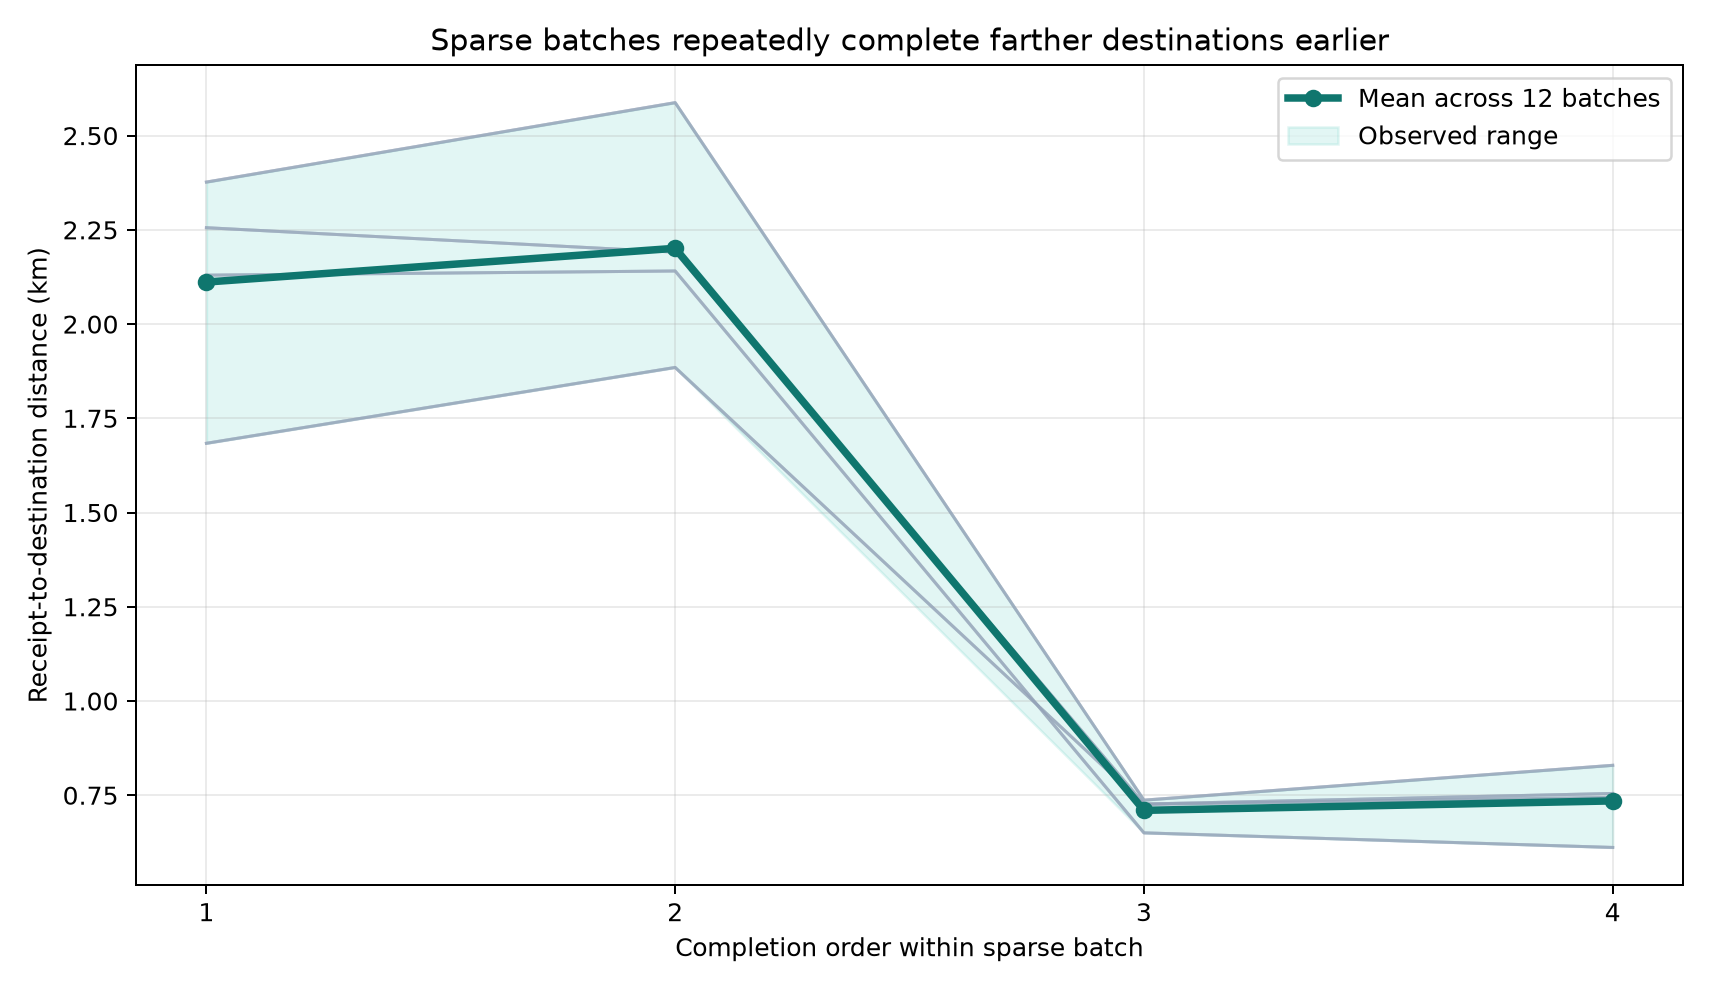

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
d = df.copy()
d['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])
for c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])
def haversine(lon1,lat1,lon2,lat2):
    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))
d['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)
sparse=d.groupby(['ds','receipt_time']).filter(lambda q:len(q)==4).sort_values(['ds','receipt_time','sign_time'])
sparse['completion_order']=sparse.groupby(['ds','receipt_time']).cumcount()+1
sparse.groupby('completion_order').destination_distance_km.mean().plot(marker='o'); plt.ylabel('Distance (km)'); plt.grid(alpha=.25); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/sparse_distance_by_completion_order.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "comparative",
  "insight_type": "factor_relationship",
  "insight": "When receipt activity is sparse, the courier tends to complete longer-distance destinations earlier in each batch than shorter-distance destinations.",
  "insight_value": {
    "sparse_batches": 12,
    "completion_order_pattern": "farther destinations precede nearer destinations in every batch"
  },
  "plot": {
    "plot_type": "ordered_profile_chart",
    "title": "Destination Distance by Completion Order Across Sparse Batches",
    "file": "visualizations/sparse_distance_by_completion_order.png",
    "description": "All twelve batch profiles and their mean show the repeated distance-order relationship."
  },
  "question": "How does receipt-to-destination distance change across completion order in repeated sparse batches?",
  "actionable_insight": "Compare the distance profile within each batch and verify that the pattern recurs across courier-days.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nd = df.copy()\nd['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])\nfor c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])\ndef haversine(lon1,lat1,lon2,lat2):\n    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)\n    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2\n    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))\nd['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)\nsparse=d.groupby(['ds','receipt_time']).filter(lambda q:len(q)==4).sort_values(['ds','receipt_time','sign_time'])\nsparse['completion_order']=sparse.groupby(['ds','receipt_time']).cumcount()+1\nsparse.groupby('completion_order').destination_distance_km.mean().plot(marker='o'); plt.ylabel('Distance (km)'); plt.grid(alpha=.25); plt.show()\n",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "completion_time",
    "destination_position",
    "gps_time",
    "gps_position",
    "task_id",
    "courier_id"
  ]
}

### **Question 3**: Does the courier separate dense receipt collection from delivery, or interleave the two activities?

#### Analysis action

Compare each completion time with the final receipt time of its dense period and verify recurrence across days.

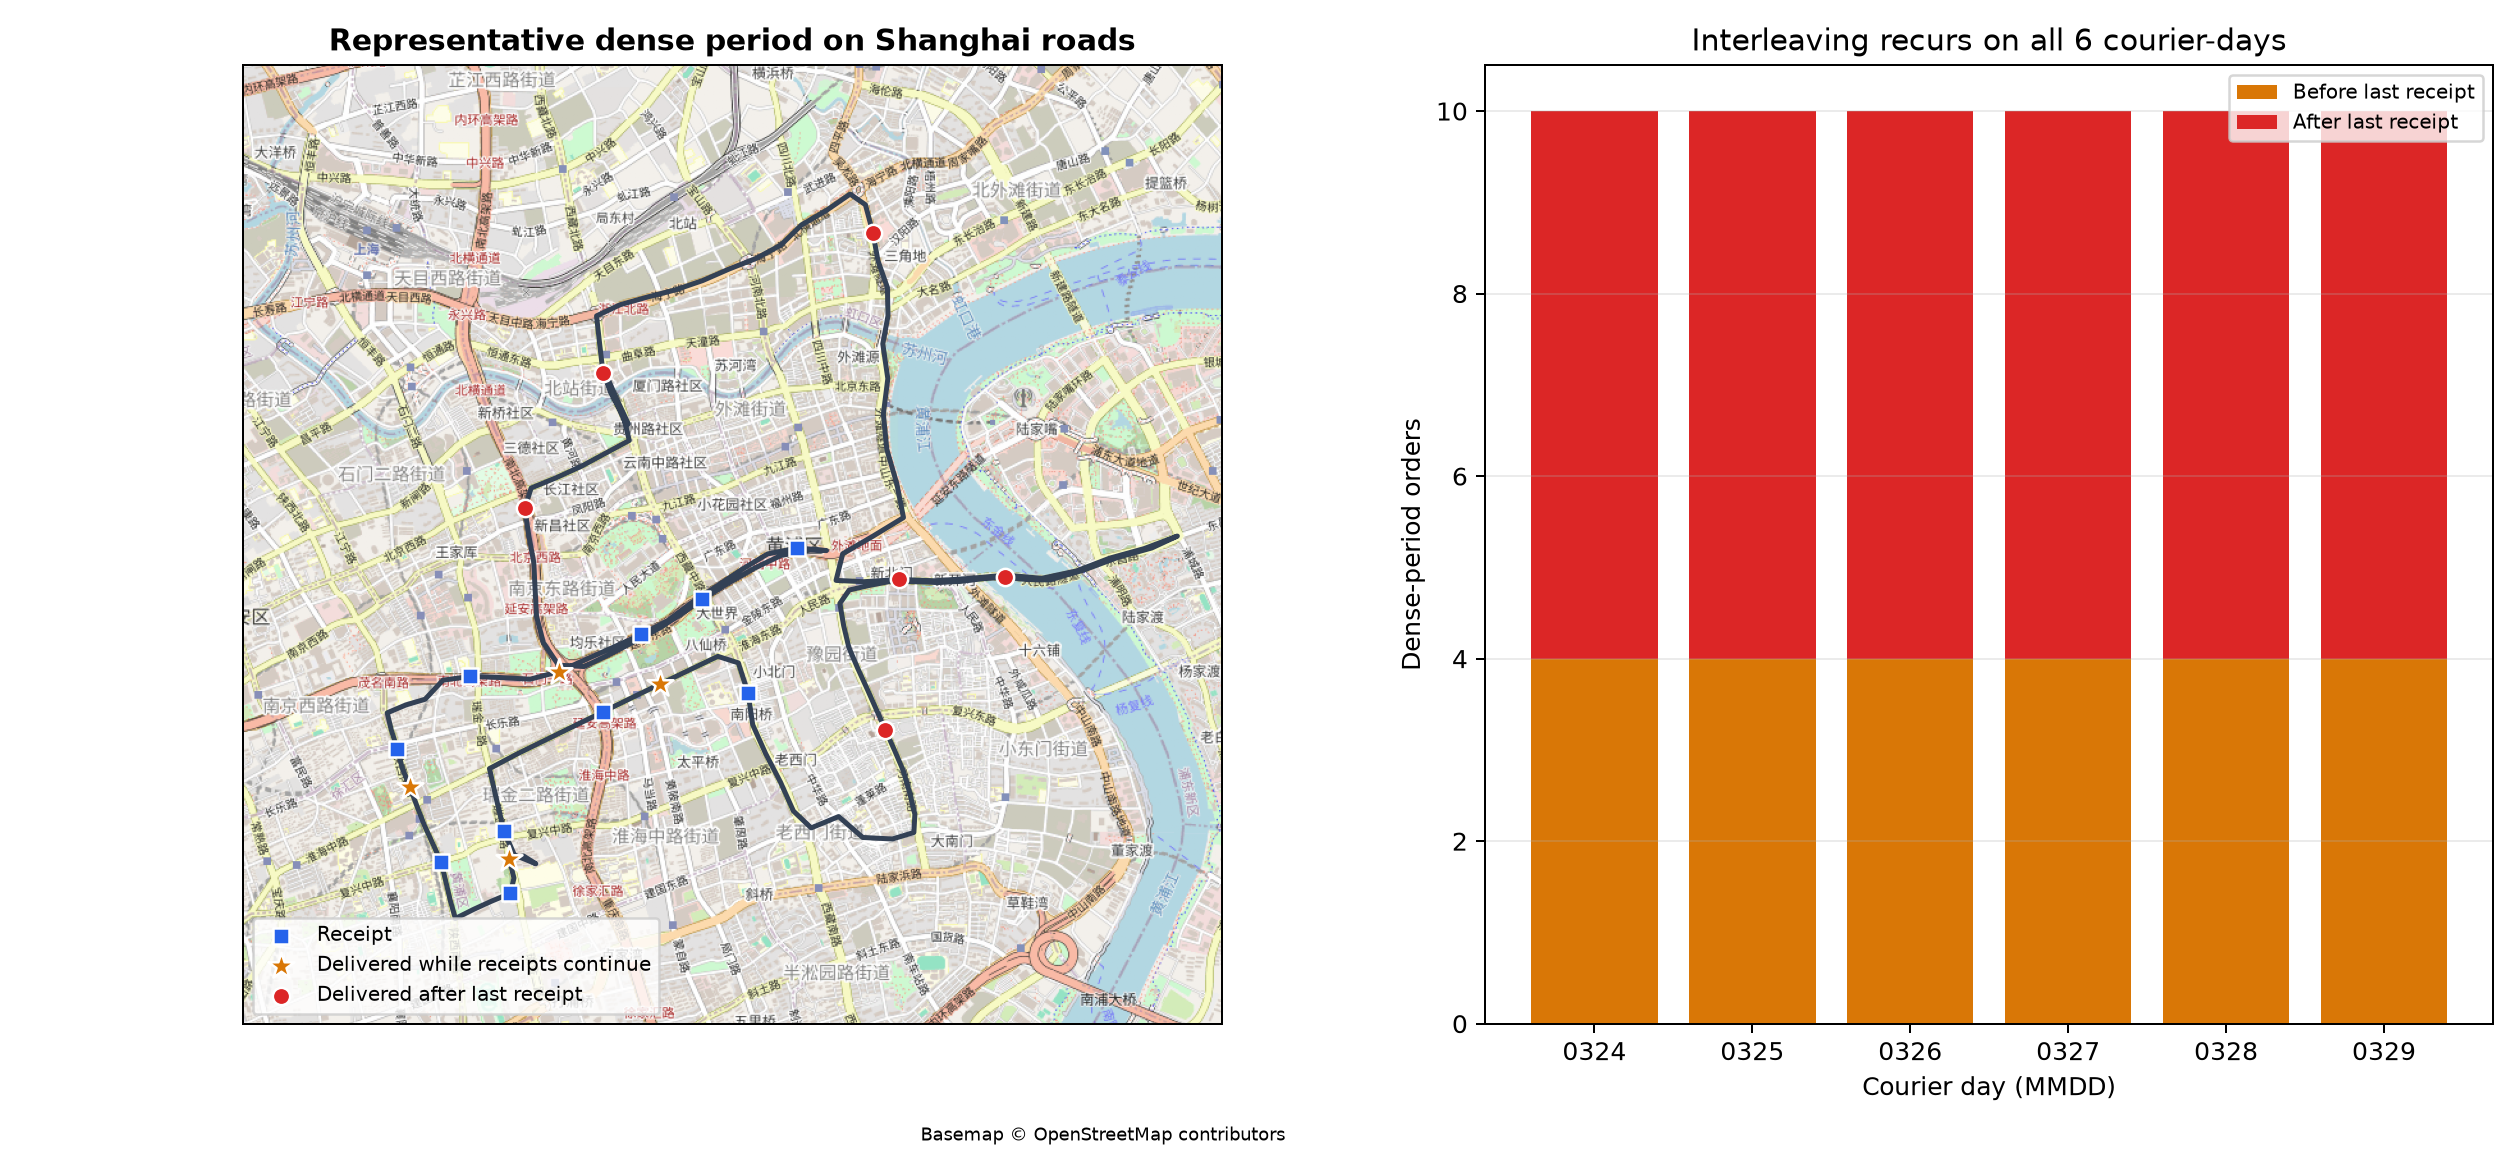

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
d = df.copy()
d['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])
for c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])
def haversine(lon1,lat1,lon2,lat2):
    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)
    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))
d['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)
dense=d[d.receipt_time.dt.hour.ge(10)].copy(); last=dense.groupby('ds').receipt_time.transform('max')
dense['interleaved']=dense.sign_time<last; print(pd.crosstab(dense.ds,dense.interleaved))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/dense_receipt_then_delivery.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "sequence",
  "insight_type": "temporal_dynamics",
  "insight": "Dense receipt activity leads the courier to interleave receipt collection and delivery rather than process them as separate batches.",
  "insight_value": {
    "dense_periods": 6,
    "periods_with_interleaving": 6,
    "interleaved_deliveries_per_period": 4
  },
  "plot": {
    "plot_type": "map_and_recurrence_chart",
    "title": "Dense Receipt Activity with Interleaved Deliveries",
    "file": "visualizations/dense_receipt_then_delivery.png",
    "description": "The map shows the road-aligned sequence and day-level bars show delivery-before-last-receipt on every courier-day."
  },
  "question": "Does the courier separate dense receipt collection from delivery, or interleave the two activities?",
  "actionable_insight": "Compare each completion time with the final receipt time of its dense period and verify recurrence across days.",
  "code": "import pandas as pd\nimport numpy as np\nimport matplotlib.pyplot as plt\nd = df.copy()\nd['receipt_time'] = pd.to_datetime(d['receipt_time']); d['sign_time'] = pd.to_datetime(d['sign_time'])\nfor c in ['receipt_lng','receipt_lat','poi_lng','poi_lat']: d[c] = pd.to_numeric(d[c])\ndef haversine(lon1,lat1,lon2,lat2):\n    p1,p2=np.radians(lat1),np.radians(lat2); dp=np.radians(lat2-lat1); dl=np.radians(lon2-lon1)\n    a=np.sin(dp/2)**2+np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2\n    return 6371.0088*2*np.arctan2(np.sqrt(a),np.sqrt(1-a))\nd['destination_distance_km']=haversine(d.receipt_lng,d.receipt_lat,d.poi_lng,d.poi_lat)\ndense=d[d.receipt_time.dt.hour.ge(10)].copy(); last=dense.groupby('ds').receipt_time.transform('max')\ndense['interleaved']=dense.sign_time<last; print(pd.crosstab(dense.ds,dense.interleaved))\n",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "receipt_time",
    "courier_id",
    "gps_time",
    "gps_position",
    "completion_time",
    "destination_position",
    "task_id"
  ]
}

### Summary of Findings (Flag 3)

Across repeated courier-days, sparse batches consistently place farther destinations earlier in the completion sequence, while dense receipt periods repeatedly interleave collection and delivery instead of separating them into two stages.